# Tutorial 03a

This notebook walks through logistic regression on trip records. Run the cells from top to bottom.

The first model has two classes. The second is a multinomial logit, the several-class model from the lecture. Both use the same trips and the same train and test rows.


## Open this notebook

- **Colab.** Replace `github.com` with `githubtocolab.com` in the repository URL, then open this file. Run the setup cell so Colab can see `mode_choice.csv`.
- **On your own computer.** Open this file from the `03 Classification Models (Logistics regression and Decision Trees and Ensemble Learning)` folder, so `mode_choice.csv` sits beside the notebook.


In [1]:
from pathlib import Path
import os

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    print("Running in Google Colab")
    REPO_URL = "https://github.com/hku-kejintao/AI-Code.git"
    LESSON_DIR = "03 Classification Models (Logistics regression and Decision Trees and Ensemble Learning)"
    base = Path("/content")
    repo = base / "AI-Code"
    os.chdir(base)
    if not repo.exists():
        !git clone {REPO_URL}
    os.chdir(repo / LESSON_DIR)
else:
    print("Running on your own computer")

print("Current folder:", os.getcwd())


Running on your own computer
Current folder: /Users/jintaoke/Library/CloudStorage/OneDrive-TheUniversityOfHongKong/courses/AI course slides/course-code/AI-Code/03 Classification Models (Logistics regression and Decision Trees and Ensemble Learning)


### Check the packages

The cell should print version numbers and the word `ready`. NumPy holds arrays, pandas holds the table, Matplotlib draws the figures, and scikit-learn fits the models.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("ready")


numpy 1.26.4
pandas 2.2.2
matplotlib 3.8.4
scikit-learn 1.7.2
ready


### Install, only if the check failed

Skip this cell when the check printed `ready`. After it finishes, restart the kernel and run the cells above again.


In [3]:
%pip install numpy pandas matplotlib scikit-learn


Note: you may need to restart the kernel to use updated packages.


## The trips

`mode_choice.csv` comes from the Victorian Integrated Survey of Travel and Activity (VISTA) 2024–2025, published by the Department of Transport and Planning, Victoria, under CC BY 4.0.

Each row is one trip. The recorded modes are grouped into `car`, `walk`, `transit`, and `bike`. `active` is 1 when the mode is walk or bike, and 0 otherwise. Incomplete rows were removed. The file was shuffled once, so a cut by row number is a mixed split.

Car is the largest class. A model can look accurate by calling most trips car.


rows 17680
mode
car        13639
walk        2899
transit      813
bike         329
Name: count, dtype: int64
active share 0.183


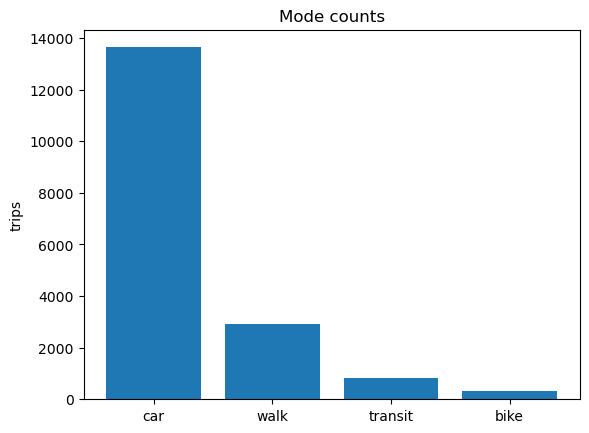

In [4]:
trips = pd.read_csv("mode_choice.csv")
print("rows", len(trips))
print(trips["mode"].value_counts())
print("active share", round(float(trips["active"].mean()), 3))

order = ["car", "walk", "transit", "bike"]
counts = trips["mode"].value_counts().reindex(order)
plt.bar(counts.index, counts.values)
plt.ylabel("trips")
plt.title("Mode counts")
plt.show()


## Train and test

Take the first 75% of the rows as the training set and the last 25% as the test set. Fit only on the training rows. The scores below are on the test rows.

The features are the trip distance and duration, the start hour, the household's vehicles and bicycles, and a few categories: purpose, day type, age group, sex, car licence, and whether the person works.


In [5]:
n_train = int(len(trips) * 0.75)
train = trips.iloc[:n_train].copy()
test = trips.iloc[n_train:].copy()
print("train", len(train), "rows")
print("test ", len(test), "rows")

num = ["distance_km", "travel_min", "start_hour", "hh_vehicles", "hh_bikes"]
cat = ["purpose", "day_type", "age_group", "sex", "car_licence", "employed"]


train 13260 rows
test  4420 rows


## A line for two classes

Logistic regression still builds a score from a weighted sum of the features. It turns that score into a probability with the logistic function. The lecture sets the label to 1 when the probability is above 0.5. Another threshold is allowed.

Here the label is `active`. Distance, time, and the counts stay in their original units. `get_dummies` turns each category into columns of zeros and ones, because the model adds a weight to each column. The test rows use the same columns. A category that appears only in the test rows is filled with zero.


## The `C` in `LogisticRegression`

The lecture minimizes the cross-entropy and a lasso penalty. The coefficient is $\lambda$:

$$
E(\mathbf{w}, w_0 \mid \mathcal{X}) + \frac{\lambda}{2}\sum_{j=1}^{D}|w_j|
$$

The intercept $w_0$ is left out of the sum. A large $\lambda$ can set some weights to zero.

`LogisticRegression(..., penalty="l1")` minimizes

$$
\|\mathbf{w}\|_1 + C \, E(\mathbf{w}, w_0 \mid \mathcal{X})
$$

Divide that objective by $C$. It matches the lecture when

$$
\lambda = \frac{2}{C}
$$

A large `C` is a small $\lambda$.

The cell below does not set `penalty`, so the fit uses the default `"l2"`. That objective is

$$
\frac{1}{2}\|\mathbf{w}\|^2 + C \, E(\mathbf{w}, w_0 \mid \mathcal{X})
$$

which is the same as adding $\frac{1}{2C}\|\mathbf{w}\|^2$ to the cross-entropy. The default `C` is 1. Four classes share one `C`, in the same way that the lecture uses one $\lambda$ for every class.


In [6]:
from sklearn.linear_model import LogisticRegression

train_ready = pd.concat([
    train[num],
    pd.get_dummies(train[cat], dtype=int),
], axis=1)
test_ready = pd.concat([
    test[num],
    pd.get_dummies(test[cat], dtype=int),
], axis=1)
test_ready = test_ready.reindex(columns=train_ready.columns, fill_value=0)
print("columns", train_ready.shape[1])

binary = LogisticRegression(max_iter=2000)
binary.fit(train_ready, train["active"])
print("test accuracy", round(float(binary.score(test_ready, test["active"])), 3))


columns 44
test accuracy 0.934


Hold the other features at a typical training value, and vary the distance from 0.2 km to 10 km. Beyond that, the probability of an active trip is already near zero.

The first figure is that one traveler. Each figure after it changes one thing: the trip purpose, the number of household vehicles, then whether the person has a full car licence.


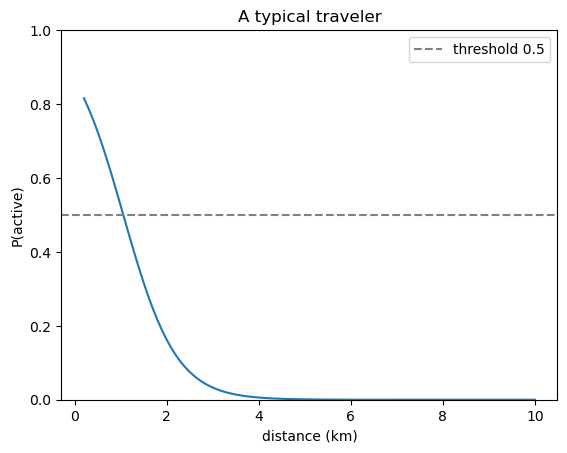

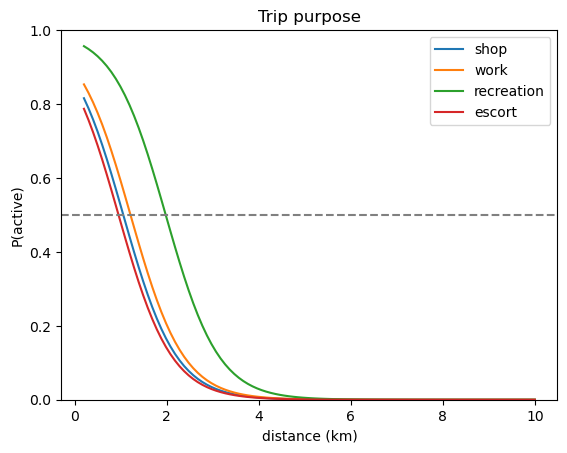

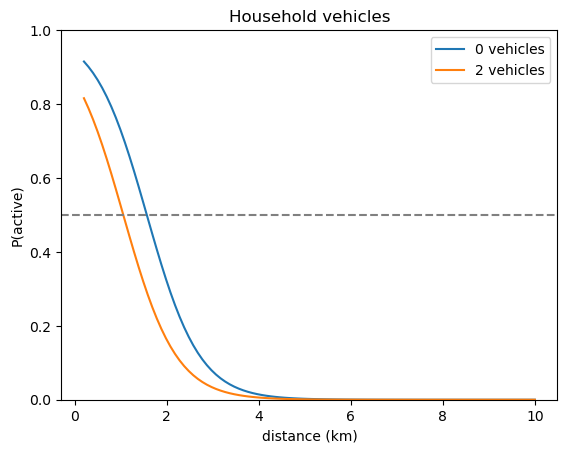

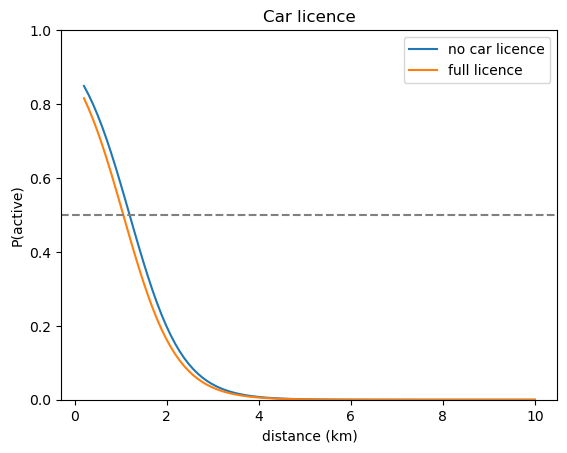

In [7]:
grid = np.linspace(0.2, 10, 100)
curve = pd.DataFrame({
    "distance_km": grid,
    "travel_min": train["travel_min"].median(),
    "start_hour": train["start_hour"].median(),
    "hh_vehicles": train["hh_vehicles"].median(),
    "hh_bikes": train["hh_bikes"].median(),
    "purpose": train["purpose"].mode().iloc[0],
    "day_type": train["day_type"].mode().iloc[0],
    "age_group": train["age_group"].mode().iloc[0],
    "sex": train["sex"].mode().iloc[0],
    "car_licence": train["car_licence"].mode().iloc[0],
    "employed": train["employed"].mode().iloc[0],
})
curve_ready = pd.concat([
    curve[num],
    pd.get_dummies(curve[cat], dtype=int),
], axis=1)
curve_ready = curve_ready.reindex(columns=train_ready.columns, fill_value=0)

active_proba = binary.predict_proba(curve_ready)[:, 1]
plt.plot(grid, active_proba)
plt.axhline(0.5, color="0.5", linestyle="--", label="threshold 0.5")
plt.xlabel("distance (km)")
plt.ylabel("P(active)")
plt.ylim(0, 1)
plt.title("A typical traveler")
plt.legend()
plt.show()

shop = curve.copy()
shop["purpose"] = "shop"
work = curve.copy()
work["purpose"] = "work"
recreation = curve.copy()
recreation["purpose"] = "recreation"
escort = curve.copy()
escort["purpose"] = "escort"
by_purpose = pd.concat([shop, work, recreation, escort], ignore_index=True)
by_purpose_ready = pd.concat([
    by_purpose[num],
    pd.get_dummies(by_purpose[cat], dtype=int),
], axis=1)
by_purpose_ready = by_purpose_ready.reindex(columns=train_ready.columns, fill_value=0)
by_purpose_proba = binary.predict_proba(by_purpose_ready)[:, 1]
n = len(grid)
plt.plot(grid, by_purpose_proba[0:n], label="shop")
plt.plot(grid, by_purpose_proba[n:2 * n], label="work")
plt.plot(grid, by_purpose_proba[2 * n:3 * n], label="recreation")
plt.plot(grid, by_purpose_proba[3 * n:4 * n], label="escort")
plt.axhline(0.5, color="0.5", linestyle="--")
plt.xlabel("distance (km)")
plt.ylabel("P(active)")
plt.ylim(0, 1)
plt.title("Trip purpose")
plt.legend()
plt.show()

no_car = curve.copy()
no_car["hh_vehicles"] = 0
two_cars = curve.copy()
two_cars["hh_vehicles"] = 2
by_vehicles = pd.concat([no_car, two_cars], ignore_index=True)
by_vehicles_ready = pd.concat([
    by_vehicles[num],
    pd.get_dummies(by_vehicles[cat], dtype=int),
], axis=1)
by_vehicles_ready = by_vehicles_ready.reindex(columns=train_ready.columns, fill_value=0)
by_vehicles_proba = binary.predict_proba(by_vehicles_ready)[:, 1]
plt.plot(grid, by_vehicles_proba[0:n], label="0 vehicles")
plt.plot(grid, by_vehicles_proba[n:2 * n], label="2 vehicles")
plt.axhline(0.5, color="0.5", linestyle="--")
plt.xlabel("distance (km)")
plt.ylabel("P(active)")
plt.ylim(0, 1)
plt.title("Household vehicles")
plt.legend()
plt.show()

no_licence = curve.copy()
no_licence["car_licence"] = "No Car Licence"
full_licence = curve.copy()
full_licence["car_licence"] = "Full Licence"
by_licence = pd.concat([no_licence, full_licence], ignore_index=True)
by_licence_ready = pd.concat([
    by_licence[num],
    pd.get_dummies(by_licence[cat], dtype=int),
], axis=1)
by_licence_ready = by_licence_ready.reindex(columns=train_ready.columns, fill_value=0)
by_licence_proba = binary.predict_proba(by_licence_ready)[:, 1]
plt.plot(grid, by_licence_proba[0:n], label="no car licence")
plt.plot(grid, by_licence_proba[n:2 * n], label="full licence")
plt.axhline(0.5, color="0.5", linestyle="--")
plt.xlabel("distance (km)")
plt.ylabel("P(active)")
plt.ylim(0, 1)
plt.title("Car licence")
plt.legend()
plt.show()


## Confusion matrix, for two classes

The fundamentals lecture already names the four cells: true positive, false positive, true negative, and false negative. The picture of those four counts is the confusion matrix. Rows are the recorded class. Columns are the predicted class.

Precision is TP / (TP + FP): among trips called active, how many really are. Recall is TP / (TP + FN): among trips that are active, how many the model finds. A lower threshold calls more trips active, so recall rises and precision usually falls.


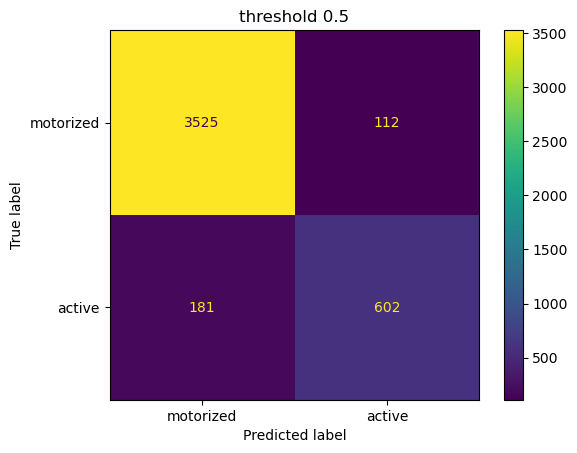

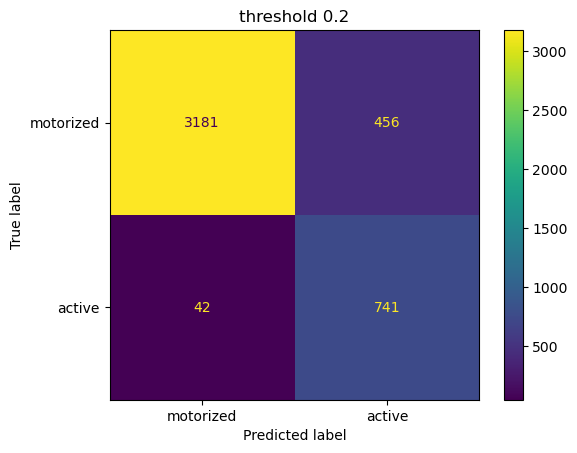

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

active_score = binary.predict_proba(test_ready)[:, 1]

pred_05 = (active_score >= 0.5).astype(int)
cm_05 = confusion_matrix(test["active"], pred_05, labels=[0, 1])
ConfusionMatrixDisplay(cm_05, display_labels=["motorized", "active"]).plot()
plt.title("threshold 0.5")
plt.show()

pred_02 = (active_score >= 0.2).astype(int)
cm_02 = confusion_matrix(test["active"], pred_02, labels=[0, 1])
ConfusionMatrixDisplay(cm_02, display_labels=["motorized", "active"]).plot()
plt.title("threshold 0.2")
plt.show()


## ROC and AUC

The ROC curve keeps the fitted probabilities and moves the threshold. The horizontal axis is the false positive rate. The vertical axis is the true positive rate, which is recall. AUC is the area under that curve. A larger area means the active trips get higher probabilities than the motorized trips, across thresholds.

This is still a two-class summary. It uses one positive class.


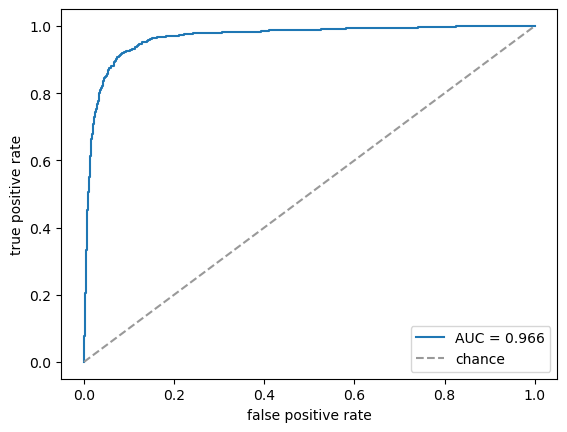

In [9]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(test["active"], active_score)
plt.plot(fpr, tpr, label=f"AUC = {auc(fpr, tpr):.3f}")
plt.plot([0, 1], [0, 1], color="0.6", linestyle="--", label="chance")
plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.legend()
plt.show()


## Four modes: multinomial logit

The lecture writes the probability of class k with the softmax function. Each class has its own weights. The four probabilities add to 1. scikit-learn's logistic regression uses that model as soon as the labels have more than two values.

Fit it on the same columns. The distance table from above now returns four curves.

The fit below uses that same default, `penalty="l2"` and `C = 1`. One `C` is shared by all four classes. With `penalty="l1"` the lecture's $\lambda$ is still $2/C$.


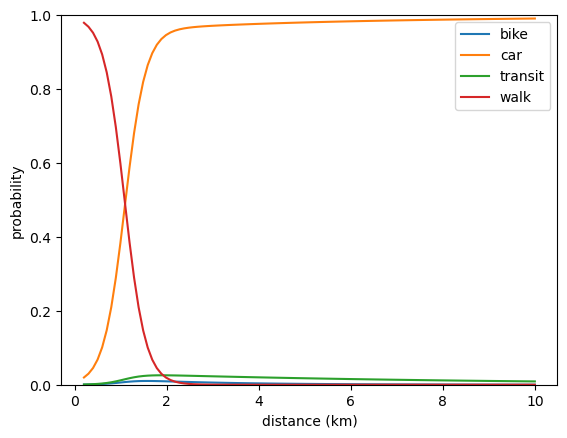

In [10]:
multi = LogisticRegression(max_iter=2000)
multi.fit(train_ready, train["mode"])

class_proba = multi.predict_proba(curve_ready)
for i, name in enumerate(multi.classes_):
    plt.plot(grid, class_proba[:, i], label=name)
plt.xlabel("distance (km)")
plt.ylabel("probability")
plt.ylim(0, 1)
plt.legend()
plt.show()


## Confusion matrix, for several classes

The lecture figure is a 2 by 2 table. With four modes the table is 4 by 4. The row is the recorded mode. The column is the predicted mode. A trip on the diagonal was classified correctly. A trip off the diagonal was given some other mode.

Read one row to see where that mode goes. Read one column to see what the model is calling by that name. Accuracy only counts the diagonal. On this table the car row and the car column are large, so a high accuracy can hide a weak transit or bike row.


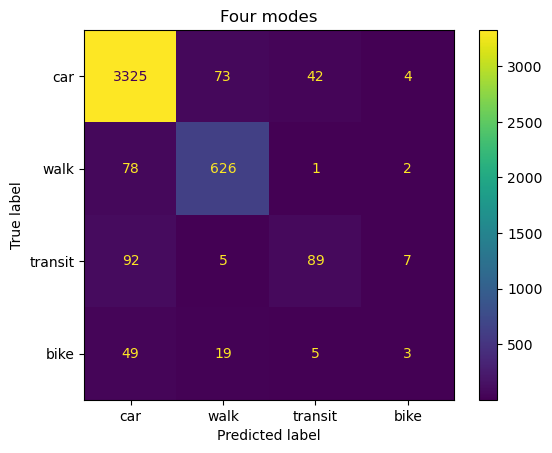

          car  walk  transit  bike
car      3325    73       42     4
walk       78   626        1     2
transit    92     5       89     7
bike       49    19        5     3


In [11]:
mode_order = ["car", "walk", "transit", "bike"]
mode_pred = multi.predict(test_ready)
cm = confusion_matrix(test["mode"], mode_pred, labels=mode_order)
ConfusionMatrixDisplay(cm, display_labels=mode_order).plot()
plt.title("Four modes")
plt.show()
print(pd.DataFrame(cm, index=mode_order, columns=mode_order))


## Precision, recall, and F1

Take one mode as the positive class and treat the other three as negative. Precision and recall then use the same two formulas as in the two-class case.

F1 puts those two numbers together. It is high only when both are high.

$$
F_1 = \frac{2 \cdot \text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}
$$

Each mode has its own F1. Macro F1 is the ordinary average of the four, so each mode has the same weight. Macro F1 is the score used to compare models later.

The two-class model has one positive class, so it has one F1. The same formula applies. It is printed here next to the four-class scores.


In [12]:
from sklearn.metrics import precision_recall_fscore_support, f1_score, accuracy_score

precision, recall, f1, support = precision_recall_fscore_support(
    test["active"], pred_05, labels=[0, 1], zero_division=0
)
print("Two classes, threshold 0.5")
print(pd.DataFrame(
    {"precision": precision, "recall": recall, "F1": f1, "trips": support},
    index=["motorized", "active"],
).round(3))
print("accuracy", round(float(accuracy_score(test["active"], pred_05)), 3))
print("F1 of active", round(float(f1[1]), 3))

precision, recall, f1, support = precision_recall_fscore_support(
    test["mode"], mode_pred, labels=mode_order, zero_division=0
)
print()
print("Four modes")
print(pd.DataFrame(
    {"precision": precision, "recall": recall, "F1": f1, "trips": support},
    index=mode_order,
).round(3))
print("accuracy", round(float(accuracy_score(test["mode"], mode_pred)), 3))
print("macro F1", round(float(f1_score(test["mode"], mode_pred, average="macro")), 3))

# Accuracy follows the large car class.
# Macro F1 gives each mode the same weight, so transit and bike pull it down.


Two classes, threshold 0.5
           precision  recall     F1  trips
motorized      0.951   0.969  0.960   3637
active         0.843   0.769  0.804    783
accuracy 0.934
F1 of active 0.804

Four modes
         precision  recall     F1  trips
car          0.938   0.965  0.952   3444
walk         0.866   0.885  0.876    707
transit      0.650   0.461  0.539    193
bike         0.188   0.039  0.065     76
accuracy 0.915
macro F1 0.608
